# Random Forest Classifier

We use this model in order to predict whether an offense will pass or run using only information available before the snap (`is_pass`).

A random forest averages many decision trees, each trained on a random sample of plays and a random subset of features at each split. It can capture the interactions and thresholds that football decisions involve (for example, *3rd and short near the goal line*) without us writing them in by hand, which a logistic regression cannot do.

How it is evaluated (same as the other classification models):
- Train on the 20 training games, test once on the 6 held-out games. Plays from one game never appear in both sets.
- Same preprocessing, same metrics (accuracy, precision, recall, F1, ROC AUC) as `02_play_prediction.ipynb`.
- Hyperparameters are tuned **inside the training set only**, with 5-fold cross-validation that keeps each game's plays together (`GroupKFold` on `gameId`). The test games are not used for any choice.
- Models are selected on ROC AUC because it does not depend on the 0.5 probability threshold. About 43% of plays are passes, so accuracy alone is a weak yardstick (always guessing "run" is already right ~58% of the time).

In [14]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
TARGET = "is_pass"

project_dir = Path.cwd().parent
fig_dir = project_dir / "reports" / "figures"
table_dir = project_dir / "reports" / "tables"
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

## Load Data

In [15]:
# Load the modeling dataset and the classification features chosen during EDA
df = pd.read_csv(project_dir / "data" / "processed" / "model_df.csv")

with open(project_dir / "data" / "processed" / "classification_feature_lists_after_eda.json") as f:
    feature_info = json.load(f)["classification"]

features = feature_info["features"]
numeric_features = feature_info["numeric"]
categorical_features = feature_info["categorical"]
binary_features = feature_info["binary"]

# Same train/test split as the other classification models: whole games, never single plays
train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

X_train, y_train = train_df[features], train_df[TARGET]
X_test, y_test = test_df[features], test_df[TARGET]

# Game ids for cross-validation inside the training set
groups_train = train_df["gameId"]

# Sanity checks
assert set(train_df["gameId"]).isdisjoint(set(test_df["gameId"])), "a game appears in both train and test"
assert set(y_train.unique()) <= {0, 1} and set(y_test.unique()) <= {0, 1}
assert not {"yardsGained", "ppa", "playType", "playText", "is_pass"} & set(features), "post-snap column in features"

print(f"Training: {X_train.shape[0]} plays from {train_df['gameId'].nunique()} games")
print(f"Testing:  {X_test.shape[0]} plays from {test_df['gameId'].nunique()} games")
print(f"Features: {len(features)}  |  training pass rate {y_train.mean():.3f}, testing pass rate {y_test.mean():.3f}")

Training: 1395 plays from 20 games
Testing:  378 plays from 6 games
Features: 24  |  training pass rate 0.431, testing pass rate 0.418


## Preprocessing

In [16]:
numeric_missing = ["prev_yards", "pass_rate_last5", "pass_rate_game_so_far",
                   "team_prior_pass_rate", "team_prior_pass_rate_down"]
binary_missing = ["prev_call_1", "prev_call_2", "prev_call_3"]
binary_no_missing = [c for c in binary_features if c not in binary_missing]

# Numeric: median imputation (+ a missing-value indicator) then standardize
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

# Categorical (down, period): one-hot encode
categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Binary features with gaps (play history): most-frequent imputation (+ indicator)
binary_missing_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent", add_indicator=True)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("binary_missing", binary_missing_pipeline, binary_missing),
        ("binary", "passthrough", binary_no_missing),
    ],
    remainder="drop",
)
# All imputers and the scaler are fit on training data only, because the preprocessor sits inside each model's Pipeline.

In [17]:
def evaluate(model, X, y):
    """Metrics at the default 0.5 threshold; ROC AUC uses predicted probabilities."""
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    metrics = {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1 Score": f1_score(y, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y, prob),
    }
    return metrics, pred, prob


def bootstrap_ci(y, pred, prob, n_boot=1000, seed=RANDOM_STATE):
    """Approximate 95% intervals for test accuracy and ROC AUC by resampling test plays.
    Plays from one game are correlated, so the true uncertainty is somewhat larger than this."""
    rng = np.random.default_rng(seed)
    y, pred, prob = np.asarray(y), np.asarray(pred), np.asarray(prob)
    acc, auc = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        acc.append((y[idx] == pred[idx]).mean())
        auc.append(roc_auc_score(y[idx], prob[idx]))
    return {"Accuracy": np.percentile(acc, [2.5, 97.5]), "ROC AUC": np.percentile(auc, [2.5, 97.5])}


def permutation_table(model, X, y, n_repeats=30):
    """How much the test ROC AUC drops when one original feature is shuffled."""
    r = permutation_importance(model, X, y, scoring="roc_auc", n_repeats=n_repeats,
                               random_state=RANDOM_STATE, n_jobs=-1)
    return (pd.DataFrame({"Feature": X.columns, "AUC drop": r.importances_mean, "Std": r.importances_std})
              .sort_values("AUC drop", ascending=False).reset_index(drop=True))


def plot_confusion(y, pred, title, path):
    cm = confusion_matrix(y, pred)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Run", "Pass"]).plot(cmap="Blues", values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_roc(curves, title, path):
    """curves: list of (label, y_true, y_prob)."""
    fig, ax = plt.subplots(figsize=(5.5, 5))
    for label, y, prob in curves:
        fpr, tpr, _ = roc_curve(y, prob)
        ax.plot(fpr, tpr, lw=2, label=f"{label} (AUC {roc_auc_score(y, prob):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC 0.500)")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(title); ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_importance(imp, title, path, top=15):
    top_imp = imp.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.barh(top_imp["Feature"], top_imp["AUC drop"], xerr=top_imp["Std"], color="#0072B2", ecolor="gray", capsize=2)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Drop in test ROC AUC when the feature is shuffled")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

## Reference Models

In [26]:
null_model = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
null_metrics, _, _ = evaluate(null_model, X_test, y_test)
null_metrics["ROC AUC"] = np.nan

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=np.inf, max_iter=3000, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)
lr_metrics, lr_pred, lr_prob = evaluate(logistic_model, X_test, y_test)

reference = pd.DataFrame({"Null Model": null_metrics, "Logistic Regression": lr_metrics}).T
display(reference.round(4))


,Accuracy,Precision,Recall,F1 Score,ROC AUC
Null Model,0.5820,0.0000,0.0000,0.0000,NaN
Logistic Regression,0.6402,0.5982,0.4241,0.4963,0.6522


## Tuning with cross validation by game

| Hyperparameter | Meaning | Values tried |
|---|---|---|
| `max_depth` | How many questions a tree may ask in a row | 3, 5, 8, no limit |
| `min_samples_leaf` | Minimum plays in a final leaf; larger = smoother, less memorizing | 1, 5, 10, 20 |
| `max_features` | Features each split may look at; smaller = more varied trees | square root of the feature count, or half of them |


In [19]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=1)),
])

param_grid = {
    "classifier__max_depth": [3, 5, 8, None],
    "classifier__min_samples_leaf": [1, 5, 10, 20],
    "classifier__max_features": ["sqrt", 0.5],
}

cv = GroupKFold(n_splits=5)

search = GridSearchCV(rf_pipeline, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)

t0 = time.perf_counter()
search.fit(X_train, y_train, groups=groups_train)
tuning_seconds = time.perf_counter() - t0

print(f"Tried {len(search.cv_results_['params'])} settings x 5 folds in {tuning_seconds:.0f} s")
print("Best settings:", {k.replace('classifier__', ''): v for k, v in search.best_params_.items()})
print(f"Best cross-validated ROC AUC (training games only): {search.best_score_:.4f}")

Tried 32 settings x 5 folds in 24 s
Best settings: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Best cross-validated ROC AUC (training games only): 0.6992


In [20]:
cv_table = pd.DataFrame(search.cv_results_)
cv_table = cv_table.rename(columns={
    "param_classifier__max_depth": "max_depth",
    "param_classifier__min_samples_leaf": "min_samples_leaf",
    "param_classifier__max_features": "max_features",
    "mean_test_score": "CV AUC (mean)",
    "std_test_score": "CV AUC (std across folds)",
})
cv_table = cv_table[["max_depth", "min_samples_leaf", "max_features", "CV AUC (mean)",
                     "CV AUC (std across folds)", "rank_test_score"]].sort_values("rank_test_score")
cv_table.to_csv(table_dir / "classification_rf_cv_results.csv", index=False)

print("Top 8 settings:")
display(cv_table.head(8).round(4))
print("Worst setting for comparison:")
display(cv_table.tail(1).round(4))

Top 8 settings:


,max_depth,min_samples_leaf,max_features,CV AUC (mean),CV AUC (std across folds),rank_test_score
16,8,1,sqrt,0.6992,0.0263,1
25,None,5,sqrt,0.6983,0.0235,2
17,8,5,sqrt,0.6980,0.0252,3
24,None,1,sqrt,0.6962,0.0262,4
8,5,1,sqrt,0.6958,0.0284,5
18,8,10,sqrt,0.6949,0.0286,6
21,8,5,0.5,0.6948,0.0276,7
26,None,10,sqrt,0.6947,0.0256,8


Worst setting for comparison:


,max_depth,min_samples_leaf,max_features,CV AUC (mean),CV AUC (std across folds),rank_test_score
7,3,20,0.5,0.6727,0.0358,32


## Final model performance

In [21]:
best_rf = search.best_estimator_

# Time one clean fit with the chosen settings (to report how expensive the model is)
t0 = time.perf_counter()
clone(best_rf).fit(X_train, y_train)
fit_seconds = time.perf_counter() - t0

train_metrics, _, _ = evaluate(best_rf, X_train, y_train)
rf_metrics, rf_pred, rf_prob = evaluate(best_rf, X_test, y_test)

print(f"Accuracy:  {rf_metrics['Accuracy']:.4f}")
print(f"Precision: {rf_metrics['Precision']:.4f}")
print(f"Recall:    {rf_metrics['Recall']:.4f}")
print(f"F1 Score:  {rf_metrics['F1 Score']:.4f}")
print(f"ROC AUC:   {rf_metrics['ROC AUC']:.4f}")
print()
print(classification_report(y_test, rf_pred, labels=[0, 1], target_names=["Run", "Pass"], zero_division=0))

gap = pd.DataFrame({
    "ROC AUC": [train_metrics["ROC AUC"], search.best_score_, rf_metrics["ROC AUC"]],
    "Accuracy": [train_metrics["Accuracy"], np.nan, rf_metrics["Accuracy"]],
}, index=["Training plays (fit on these)", "Cross-validation (unseen games, training set)", "Test games (unseen)"])
print("Does it overfit? Compare how it does on plays it has seen vs plays it has not:")
display(gap.round(4))

Accuracy:  0.6667
Precision: 0.6270
Recall:    0.5000
F1 Score:  0.5563
ROC AUC:   0.6787

              precision    recall  f1-score   support

         Run       0.69      0.79      0.73       220
        Pass       0.63      0.50      0.56       158

    accuracy                           0.67       378
   macro avg       0.66      0.64      0.64       378
weighted avg       0.66      0.67      0.66       378

Does it overfit? Compare how it does on plays it has seen vs plays it has not:


,ROC AUC,Accuracy
Training plays (fit on these),0.9556,0.8645
"Cross-validation (unseen games, training set)",0.6992,NaN
Test games (unseen),0.6787,0.6667


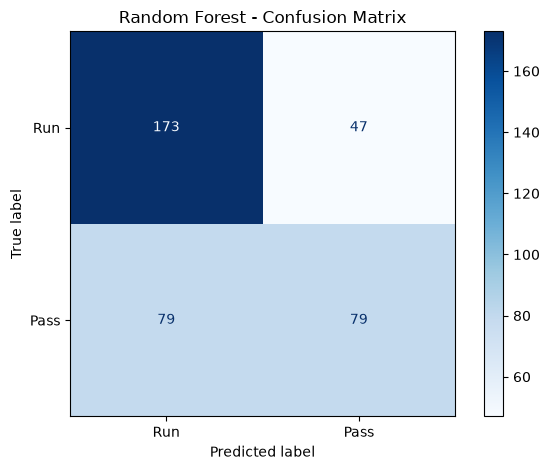

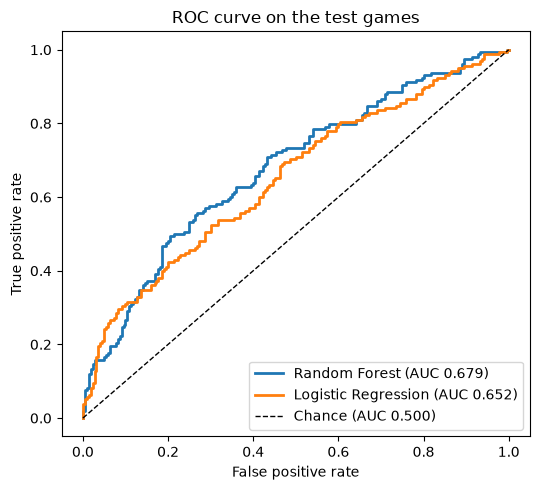

In [22]:
plot_confusion(y_test, rf_pred, "Random Forest - Confusion Matrix", fig_dir / "classification_rf_confusion_matrix.png")

plot_roc([("Random Forest", y_test, rf_prob), ("Logistic Regression", y_test, lr_prob)],
         "ROC curve on the test games", fig_dir / "classification_rf_roc_curve.png")

In [23]:
ci = bootstrap_ci(y_test, rf_pred, rf_prob)
ci_lr = bootstrap_ci(y_test, lr_pred, lr_prob)

# Same resamples for both models -> paired difference in AUC
rng = np.random.default_rng(RANDOM_STATE)
diffs = []
yt = np.asarray(y_test)
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() == yt[idx].max():
        continue
    diffs.append(roc_auc_score(yt[idx], rf_prob[idx]) - roc_auc_score(yt[idx], lr_prob[idx]))
diff_lo, diff_hi = np.percentile(diffs, [2.5, 97.5])

print(f"Random Forest       accuracy {rf_metrics['Accuracy']:.3f}  (95% interval {ci['Accuracy'][0]:.3f} to {ci['Accuracy'][1]:.3f})")
print(f"Random Forest       ROC AUC  {rf_metrics['ROC AUC']:.3f}  (95% interval {ci['ROC AUC'][0]:.3f} to {ci['ROC AUC'][1]:.3f})")
print(f"Logistic Regression ROC AUC  {lr_metrics['ROC AUC']:.3f}  (95% interval {ci_lr['ROC AUC'][0]:.3f} to {ci_lr['ROC AUC'][1]:.3f})")
print(f"AUC difference (forest - logistic): {np.mean(diffs):+.3f}  (95% interval {diff_lo:+.3f} to {diff_hi:+.3f})")
if diff_lo > 0:
    print("-> The forest is better than logistic regression beyond sampling noise.")
elif diff_hi < 0:
    print("-> The forest is worse than logistic regression beyond sampling noise.")
else:
    print("-> The interval includes 0: on this test set the forest and logistic regression are not clearly different.")

Random Forest       accuracy 0.667  (95% interval 0.622 to 0.714)
Random Forest       ROC AUC  0.679  (95% interval 0.628 to 0.732)
Logistic Regression ROC AUC  0.652  (95% interval 0.598 to 0.704)
AUC difference (forest - logistic): +0.026  (95% interval -0.009 to +0.062)
-> The interval includes 0: on this test set the forest and logistic regression are not clearly different.


## Feature importance

,Feature,AUC drop,Std
0,down,0.0267,0.0064
1,team_prior_pass_rate_down,0.0196,0.0051
2,distance,0.0171,0.0088
3,sec_left_game,0.0155,0.0118
4,short_yardage,0.0147,0.0086
5,prev_yards,0.0109,0.0050
6,pass_rate_last5,0.0043,0.0025
7,yardsToGoal,0.0035,0.0066
8,period,0.0032,0.0047
9,two_minute,0.0028,0.0017


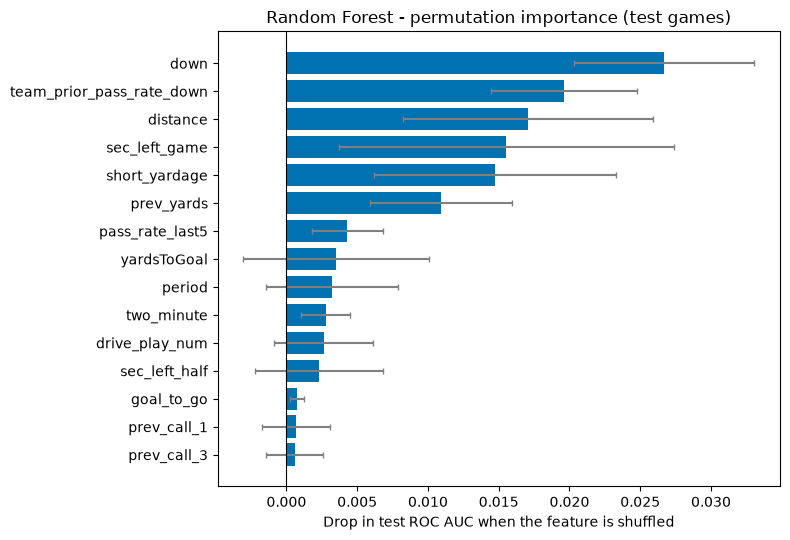

In [24]:
rf_importance = permutation_table(best_rf, X_test, y_test)
rf_importance.to_csv(table_dir / "classification_rf_permutation_importance.csv", index=False)

display(rf_importance.head(15).round(4))
plot_importance(rf_importance, "Random Forest - permutation importance (test games)",
                fig_dir / "classification_rf_permutation_importance.png")

## Save results

In [25]:
pd.DataFrame([rf_metrics]).to_csv(table_dir / "classification_results_random_forest.csv", index=False)

details = {
    "best_params": {k.replace("classifier__", ""): (None if v is None else v) for k, v in search.best_params_.items()},
    "cv_roc_auc": float(search.best_score_),
    "train_metrics": {k: float(v) for k, v in train_metrics.items()},
    "test_metrics": {k: float(v) for k, v in rf_metrics.items()},
    "test_accuracy_ci95": [float(x) for x in ci["Accuracy"]],
    "test_auc_ci95": [float(x) for x in ci["ROC AUC"]],
    "auc_diff_vs_logistic_ci95": [float(diff_lo), float(diff_hi)],
    "n_estimators": 500,
    "tuning_seconds": round(tuning_seconds, 1),
    "single_fit_seconds": round(fit_seconds, 2),
    "random_state": RANDOM_STATE,
}
with open(table_dir / "classification_random_forest_details.json", "w") as f:
    json.dump(details, f, indent=2)

summary = pd.concat([reference, pd.DataFrame({"Random Forest": rf_metrics}).T])
display(summary.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Null Model,0.5820,0.0000,0.0000,0.0000,NaN
Logistic Regression,0.6402,0.5982,0.4241,0.4963,0.6522
Random Forest,0.6667,0.6270,0.5000,0.5563,0.6787
